# Does recommended listening broaden or narrow taste? Three methods, one question

**Question.** For the same users, is what the recommender plays (`is_organic = 0`) *broader* or *narrower* than what
they choose themselves (`is_organic = 1`)?

We answer it with three methods and then compare the answers:

| # | Method | Course link | What it measures |
|---|---|---|---|
| A | Diversity metrics (with sensitivity checks) | baseline | how many different artists, how evenly, how mainstream |
| B | MinHash and LSH on user artist sets (own implementation) | Week 4 | do users become *more alike*? |
| C | Frequent itemsets: A-Priori and PCY on session baskets (own implementation) | Week 5 | do a few artist combinations dominate? |

**Operational definitions** (so "broader" and "narrower" mean something testable)

* **Broader** = more distinct artists, higher entropy, fewer shared patterns, users less alike.
* **Narrower** = fewer distinct artists, a few artist combinations explain much of the listening, users more alike.

**Fairness rules used throughout**

1. Only *real listens* (played at least `REAL_PCT` percent).
2. Compare **distinct** tracks/artists, not raw plays (organic listening is mostly replays, see notebook 01).
3. Same users in both streams, equal-sized samples, and for baskets the same basket-size distribution.
4. Everything is an association, not proof of causation.

Run time: roughly 6-10 minutes. Memory: 5-7 GB.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats
from scipy.sparse import csr_matrix

# ---------------- parameters (change here, then Run All) ----------------
REAL_PCT = 50            # real listen = at least this % played
SESSION_GAP_S = 30 * 60  # new session after a gap longer than this
SEED = 42

N_TRACKS = 100           # method A: distinct tracks per user and stream
K_ART = 50               # method B: artists per user and stream (equal-size sets)
T_SIM = 0.15             # method B: "similar users" = exact Jaccard >= T_SIM
N_HASH = 120             # method B: MinHash signature length
CAP = 15                 # method C: max distinct artists per basket
MAX_BASKETS_PER_USER = 100
SUPPORTS = [0.0002, 0.0005, 0.001, 0.002]   # method C: relative support thresholds
SUP = 0.0005             # method C: the main support threshold

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {"organic": "#2a9d8f", "recommended": "#e76f51"}

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find data/raw/yambda above " + str(Path.cwd()))
    ROOT = ROOT.parent
DATA = ROOT / "data" / "raw" / "yambda"
verdict = []   # rows of the final comparison table


def add_verdict(method, metric, organic, recommended, higher_means):
    """higher_means: 'broader' or 'narrower' (what a higher value of the metric indicates)."""
    rec_higher = recommended > organic
    broader = rec_higher if higher_means == "broader" else not rec_higher
    verdict.append({"method": method, "metric": metric, "organic": organic, "recommended": recommended,
                    "relative difference": (recommended - organic) / abs(organic) if organic else np.nan,
                    "recommended is": "broader" if broader else "narrower"})


def rank_in_group(g):
    """Position of every element inside its group, keeping the original order within a group."""
    order = np.argsort(g, kind="stable")
    gs = g[order]
    start = np.r_[0, np.flatnonzero(gs[1:] != gs[:-1]) + 1]
    sizes = np.diff(np.r_[start, len(gs)])
    rank = np.empty(len(g), dtype=np.int64)
    rank[order] = np.arange(len(gs)) - np.repeat(start, sizes)
    return rank

print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 0. Load listens, artists and sessions

In [2]:
t0 = time.time()
cols = ["uid", "item_id", "timestamp", "is_organic", "played_ratio_pct", "event_type"]
df = pq.read_table(DATA / "flat/50m/multi_event.parquet", columns=cols).to_pandas()
df = df[df["event_type"] == "listen"].drop(columns="event_type").reset_index(drop=True)

art = pd.read_parquet(DATA / "artist_item_mapping.parquet").drop_duplicates("item_id")
item_art = np.full(int(df["item_id"].max()) + 1, -1, dtype=np.int32)
ids = art["item_id"].to_numpy(); ok = ids < len(item_art)
item_art[ids[ok]] = art["artist_id"].to_numpy()[ok]

# plain numpy arrays (the data is sorted by user, then time)
item_arr = df["item_id"].to_numpy()
org_arr = df["is_organic"].to_numpy().astype(np.int8)
ratio_arr = df["played_ratio_pct"].to_numpy().astype(np.float32)
art_arr = item_art[item_arr]
ts = df["timestamp"].to_numpy().astype(np.int64)
uid = df["uid"].to_numpy()
new_user = np.empty(len(uid), dtype=bool); new_user[0] = True; new_user[1:] = uid[1:] != uid[:-1]
uidx_arr = (np.cumsum(new_user) - 1).astype(np.int32)
n_users = int(uidx_arr[-1]) + 1
del df

# sessions: a gap of more than SESSION_GAP_S starts a new one
new_sess = np.empty(len(ts), dtype=bool); new_sess[0] = True
new_sess[1:] = new_user[1:] | ((ts[1:] - ts[:-1]) > SESSION_GAP_S)
sid_arr = (np.cumsum(new_sess) - 1).astype(np.int64)

# number of distinct users per track (popularity), from distinct (user, track) pairs
key = uidx_arr.astype(np.int64) * (1 << 32) + item_arr
uniq = np.unique(key); del key
item_users = np.bincount((uniq & 0xFFFFFFFF).astype(np.int64), minlength=len(item_art))
del uniq
is_top = item_users >= np.quantile(item_users[item_users > 0], 0.99)   # top 1% most popular tracks
print(f"{len(ts):,} listens, {n_users:,} users, {sid_arr[-1] + 1:,} sessions  ({time.time() - t0:.0f} s)")

46,467,212 listens, 9,238 users, 2,452,609 sessions  (19 s)


## Method A: diversity metrics (and how robust they are)

For each user take their first `n_tracks` *distinct* real tracks in each stream and compute distinct artists, artist entropy
and mainstreamness (mean log10 of users per track). Paired comparison per user, Wilcoxon signed-rank test, bootstrap
confidence interval for the median difference.

Because this is the baseline, we also test how much the answer depends on our choices: the real-listen threshold
(30/50/80 %), the sample size (50/100/200 tracks), and removing the top 1 % most popular tracks (the popularity confound).

In [3]:
def fair_diversity(real_pct, n_tracks, drop_top=False):
    m = (ratio_arr >= real_pct) & (art_arr >= 0)
    if drop_top:
        m &= ~is_top[item_arr]
    ui, it, og, ar = uidx_arr[m], item_arr[m], org_arr[m].astype(np.int64), art_arr[m]
    k3 = (ui.astype(np.int64) << 33) | (it.astype(np.int64) << 1) | og
    _, fi = np.unique(k3, return_index=True); fi.sort()          # first real listen of each (user, track, stream)
    ui, it, og, ar = ui[fi], it[fi], og[fi], ar[fi]
    g = ui.astype(np.int64) * 2 + og
    rk = rank_in_group(g)
    cnt = np.bincount(g, minlength=2 * n_users).reshape(n_users, 2)
    elig = (cnt >= n_tracks).all(axis=1)
    sel = (rk < n_tracks) & elig[ui]
    gs, ars, its = g[sel], ar[sel], it[sel]
    uq, c = np.unique(gs * (1 << 21) + ars, return_counts=True)
    gg = uq >> 21
    p = c / n_tracks
    distinct = np.bincount(gg, minlength=2 * n_users)
    entropy = np.bincount(gg, weights=-p * np.log2(p), minlength=2 * n_users)
    mainstream = np.bincount(gs, weights=np.log10(np.maximum(item_users[its], 1)), minlength=2 * n_users) / n_tracks
    users = np.flatnonzero(elig)
    res = {}
    for name, arr in [("distinct artists", distinct), ("artist entropy (bits)", entropy), ("mainstreamness", mainstream)]:
        a2 = arr.reshape(n_users, 2)
        o, rc = a2[users, 1], a2[users, 0]
        d = rc - o
        boot = np.median(d[rng.integers(0, len(d), (1000, len(d)))], axis=1)
        res[name] = dict(users=len(users), organic=np.median(o), recommended=np.median(rc), diff=np.median(d),
                         lo=np.quantile(boot, 0.025), hi=np.quantile(boot, 0.975), share_rec_higher=(d > 0).mean(),
                         p=stats.wilcoxon(d).pvalue)
    return res

configs = [("real>=30%, 100 tracks", 30, 100, False), ("real>=50%, 100 tracks (default)", 50, 100, False),
           ("real>=80%, 100 tracks", 80, 100, False), ("real>=50%, 50 tracks", 50, 50, False),
           ("real>=50%, 200 tracks", 50, 200, False), ("real>=50%, 100 tracks, top 1% tracks removed", 50, 100, True)]
rows = []
for name, rp, nt, dt in configs:
    t1 = time.time()
    for metric, r in fair_diversity(rp, nt, dt).items():
        rows.append(dict(config=name, metric=metric, **r))
    print(f"{name}: {time.time() - t1:.0f} s")
A = pd.DataFrame(rows)

real>=30%, 100 tracks: 6 s


real>=50%, 100 tracks (default): 5 s


real>=80%, 100 tracks: 5 s


real>=50%, 50 tracks: 5 s


real>=50%, 200 tracks: 5 s


real>=50%, 100 tracks, top 1% tracks removed: 3 s


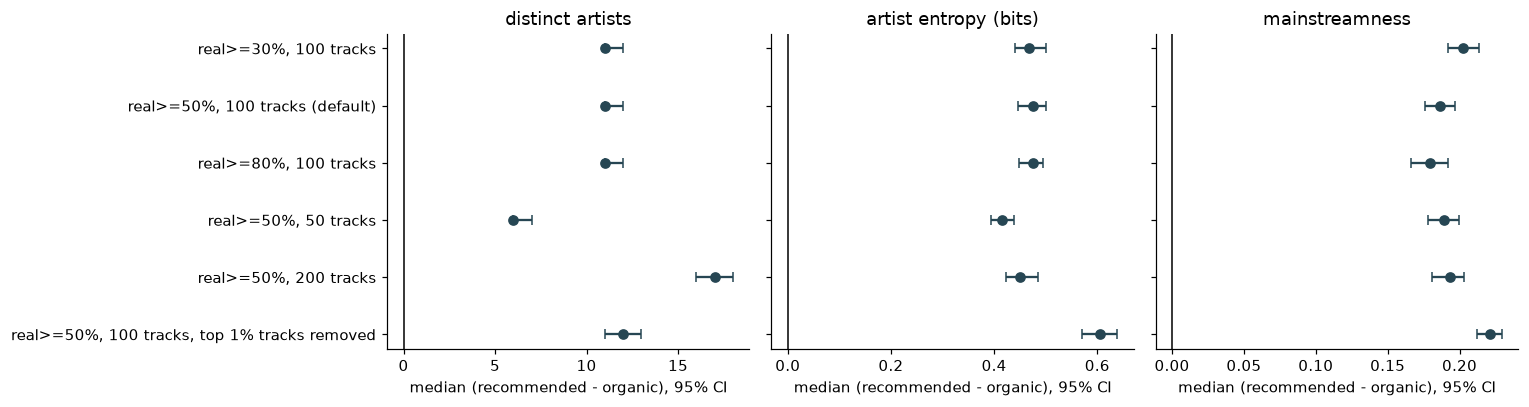

Share of users for whom the recommended stream scores HIGHER than their organic stream:
metric                                        artist entropy (bits)  distinct artists  mainstreamness
config                                                                                               
real>=30%, 100 tracks                                          81.1              76.0            75.3
real>=50%, 100 tracks (default)                                80.7              75.7            74.2
real>=80%, 100 tracks                                          80.5              75.2            73.4
real>=50%, 50 tracks                                           80.3              76.6            71.9
real>=50%, 200 tracks                                          80.2              74.0            77.2
real>=50%, 100 tracks, top 1% tracks removed                   81.3              76.3            87.9

users in the default comparison: 5,537


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
names = [c[0] for c in configs]
for a, metric in zip(ax, ["distinct artists", "artist entropy (bits)", "mainstreamness"]):
    d = A[A["metric"] == metric].set_index("config").loc[names]
    y = np.arange(len(d))[::-1]
    a.errorbar(d["diff"], y, xerr=[d["diff"] - d["lo"], d["hi"] - d["diff"]], fmt="o", color="#264653", capsize=3)
    a.axvline(0, color="k", lw=1)
    a.set(title=metric, xlabel="median (recommended - organic), 95% CI")
ax[0].set_yticks(y); ax[0].set_yticklabels(names)
plt.tight_layout(); plt.show()
default = A[A["config"] == configs[1][0]].set_index("metric")
tbl = A.pivot(index="config", columns="metric", values="share_rec_higher").loc[names]
print("Share of users for whom the recommended stream scores HIGHER than their organic stream:")
print((tbl * 100).round(1).to_string())
print(f"\nusers in the default comparison: {int(default['users'].iloc[0]):,}")
for metric in ["distinct artists", "artist entropy (bits)", "mainstreamness"]:
    add_verdict("A diversity", metric + " (median)", default.loc[metric, "organic"], default.loc[metric, "recommended"],
                "narrower" if metric == "mainstreamness" else "broader")

**Reading method A.** If the intervals stay on one side of zero in every configuration, the conclusion does not depend on our
arbitrary choices. Note that *mainstreamness* is a different property: more mainstream is not the same as narrower, it is
listed separately in the final table as "more concentrated on popular tracks".

## Method B: MinHash and LSH (Week 4)

**Idea.** If recommendations narrow taste, users should become more alike, so more pairs of users should have similar
artist sets. Each user is a *set of artists* per stream. To compare sets of equal size (Jaccard depends on size) we take
each user's first `K_ART` distinct artists in each stream.

Steps: (1) exact Jaccard for all user pairs as ground truth, (2) our own MinHash signatures and LSH banding, tuned with the
S-curve, (3) compare the two streams, using LSH to find the similar pairs and the exact values to check it.

In [5]:
m = (ratio_arr >= REAL_PCT) & (art_arr >= 0)
ui, og, ar = uidx_arr[m], org_arr[m].astype(np.int64), art_arr[m].astype(np.int64)
_, fi = np.unique(((ui.astype(np.int64) * 2 + og) << 21) | ar, return_index=True); fi.sort()
ui, og, ar = ui[fi], og[fi], ar[fi]
g = ui.astype(np.int64) * 2 + og
rk = rank_in_group(g)
cnt = np.bincount(g, minlength=2 * n_users).reshape(n_users, 2)
eligB = (cnt >= K_ART).all(axis=1)
usersB = np.flatnonzero(eligB); E = len(usersB)
pos = np.full(n_users, -1); pos[usersB] = np.arange(E)
sel = (rk < K_ART) & eligB[ui]
rows_, ars_, ogs_ = pos[ui[sel]], ar[sel], og[sel]
art_ids, art_col = np.unique(ars_, return_inverse=True)
X = {s: csr_matrix((np.ones((ogs_ == v).sum(), np.float32), (rows_[ogs_ == v], art_col[ogs_ == v])),
                   shape=(E, len(art_ids))) for s, v in [("organic", 1), ("recommended", 0)]}
print(f"{E:,} users have >= {K_ART} distinct real artists in both streams; {len(art_ids):,} artists in the sets")
assert all((np.diff(X[s].indptr) == K_ART).all() for s in X)

# exact Jaccard for every pair of users (sets all have size K_ART)
iu = np.triu_indices(E, 1)
Jd, Jv = {}, {}
for s in X:
    inter = (X[s] @ X[s].T).toarray()
    Jd[s] = inter / (2 * K_ART - inter)
    Jv[s] = Jd[s][iu]
print(f"{len(iu[0]):,} user pairs per stream")

5,887 users have >= 50 distinct real artists in both streams; 29,106 artists in the sets


17,325,441 user pairs per stream


In [6]:
rows = []
for s in Jv:
    v = Jv[s]
    rows.append({"stream": s, "mean J": v.mean(), "median J": np.median(v), "p99": np.quantile(v, 0.99),
                 "p99.9": np.quantile(v, 0.999), **{f"pairs J>={t}": (v >= t).sum() for t in (0.1, 0.15, 0.2, 0.3)}})
B = pd.DataFrame(rows).set_index("stream")
print(B.to_string(float_format=lambda x: f"{x:,.4f}"))

# paired comparison on the SAME user pairs
idx = rng.choice(len(Jv["organic"]), 400_000, replace=False)
d = Jv["recommended"][idx] - Jv["organic"][idx]
nz = d != 0
print(f"\nsame user pair: recommended more similar in {(d > 0).sum() / nz.sum():.1%} of pairs where they differ "
      f"(mean difference {d.mean():+.5f}, Wilcoxon p = {stats.wilcoxon(d[nz]).pvalue:.1e})")

# neighbours per user at threshold T_SIM
nb = {}
for s in Jd:
    M_ = Jd[s].copy(); np.fill_diagonal(M_, 0)
    nb[s] = (M_ >= T_SIM).sum(axis=1)
dn = nb["recommended"] - nb["organic"]
print(f"users with similar neighbours (J >= {T_SIM}): organic {np.mean(nb['organic'] > 0):.1%}, "
      f"recommended {np.mean(nb['recommended'] > 0):.1%};  mean neighbours/user: organic {nb['organic'].mean():.2f}, "
      f"recommended {nb['recommended'].mean():.2f}")

             mean J  median J    p99  p99.9  pairs J>=0.1  pairs J>=0.15  pairs J>=0.2  pairs J>=0.3
stream                                                                                              
organic      0.0169    0.0101 0.1111 0.1905        188748          43795         16152          2142
recommended  0.0147    0.0101 0.1111 0.1905        226410          51724         16075           894

same user pair: recommended more similar in 41.1% of pairs where they differ (mean difference -0.00222, Wilcoxon p = 0.0e+00)


users with similar neighbours (J >= 0.15): organic 38.8%, recommended 48.4%;  mean neighbours/user: organic 14.88, recommended 17.57


### Our own MinHash and LSH
`h_i(x) = (a_i x + b_i) mod p` with a prime `p`; the signature of a user is the minimum of `h_i` over their artists. The
probability that two signatures agree at one position equals their Jaccard similarity. LSH splits a signature of `N_HASH`
rows into `b` bands of `r` rows; two users become a *candidate pair* if all `r` rows of at least one band agree
(probability `1 - (1 - s^r)^b` for similarity `s`). Candidates are then checked with the exact Jaccard.

In [7]:
P = (1 << 31) - 1
hr = np.random.default_rng(SEED)
ha = hr.integers(1, P, N_HASH, dtype=np.int64); hb = hr.integers(0, P, N_HASH, dtype=np.int64)

def minhash(Xc):
    ids_ = art_ids[Xc.indices].astype(np.int64)
    sig = np.empty((N_HASH, Xc.shape[0]), dtype=np.int64)
    for i in range(N_HASH):
        sig[i] = np.minimum.reduceat((ha[i] * ids_ + hb[i]) % P, Xc.indptr[:-1])
    return sig

def lsh_candidates(sig, b, r):
    cand = []
    for j in range(b):
        _, inv = np.unique(sig[j * r:(j + 1) * r].T, axis=0, return_inverse=True)
        inv = inv.ravel(); order = np.argsort(inv, kind="stable"); s_ = inv[order]
        st = np.r_[0, np.flatnonzero(s_[1:] != s_[:-1]) + 1, len(s_)]
        for x, y in zip(st[:-1], st[1:]):
            if y - x > 1:
                mem = order[x:y]; i_, j_ = np.triu_indices(len(mem), 1)
                cand.append(np.minimum(mem[i_], mem[j_]) * E + np.maximum(mem[i_], mem[j_]))
    return np.unique(np.concatenate(cand)) if cand else np.array([], dtype=np.int64)

t1 = time.time()
sig = {s: minhash(X[s]) for s in X}
print(f"signatures: {N_HASH} hashes x {E:,} users per stream  ({time.time() - t1:.1f} s)")
# accuracy of the Jaccard estimate from signatures
sm = rng.choice(len(iu[0]), 100_000, replace=False)
for s in X:
    est = (sig[s][:, iu[0][sm]] == sig[s][:, iu[1][sm]]).mean(axis=0)
    print(f"  {s}: mean absolute error of estimated Jaccard = {np.abs(est - Jv[s][sm]).mean():.4f}")

signatures: 120 hashes x 5,887 users per stream  (0.6 s)
  organic: mean absolute error of estimated Jaccard = 0.0068
  recommended: mean absolute error of estimated Jaccard = 0.0057


In [8]:
n_pairs_total = len(iu[0])
true_pairs = {s: int((Jv[s] >= T_SIM).sum()) for s in Jv}
lsh_cfg = [(60, 2), (40, 3), (30, 4)]       # (bands b, rows r), b * r = N_HASH
rows = []
cand_store = {}
for b, r in lsh_cfg:
    assert b * r == N_HASH
    for s in sig:
        c = lsh_candidates(sig[s], b, r)
        cand_store[(b, r, s)] = c
        Jc = Jd[s][c // E, c % E]
        hits = int((Jc >= T_SIM).sum())
        rows.append({"b": b, "r": r, "stream": s, "threshold ~": round((1 / b) ** (1 / r), 3),
                     "candidates": len(c), "share of all pairs checked": len(c) / n_pairs_total,
                     "similar pairs found": hits, "similar pairs (exact)": true_pairs[s],
                     "recall": hits / true_pairs[s], "precision before check": hits / len(c)})
L = pd.DataFrame(rows)
print(L.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))

 b  r      stream  threshold ~  candidates  share of all pairs checked  similar pairs found  similar pairs (exact)  recall  precision before check
60  2     organic        0.129      696116                       0.040                38156                  43795   0.871                   0.055
60  2 recommended        0.129      683871                       0.039                46650                  51724   0.902                   0.068
40  3     organic        0.292       52065                       0.003                12554                  43795   0.287                   0.241
40  3 recommended        0.292       59270                       0.003                16055                  51724   0.310                   0.271
30  4     organic        0.427        5400                       0.000                 3138                  43795   0.072                   0.581
30  4 recommended        0.427        5971                       0.000                 3225                  51724   0

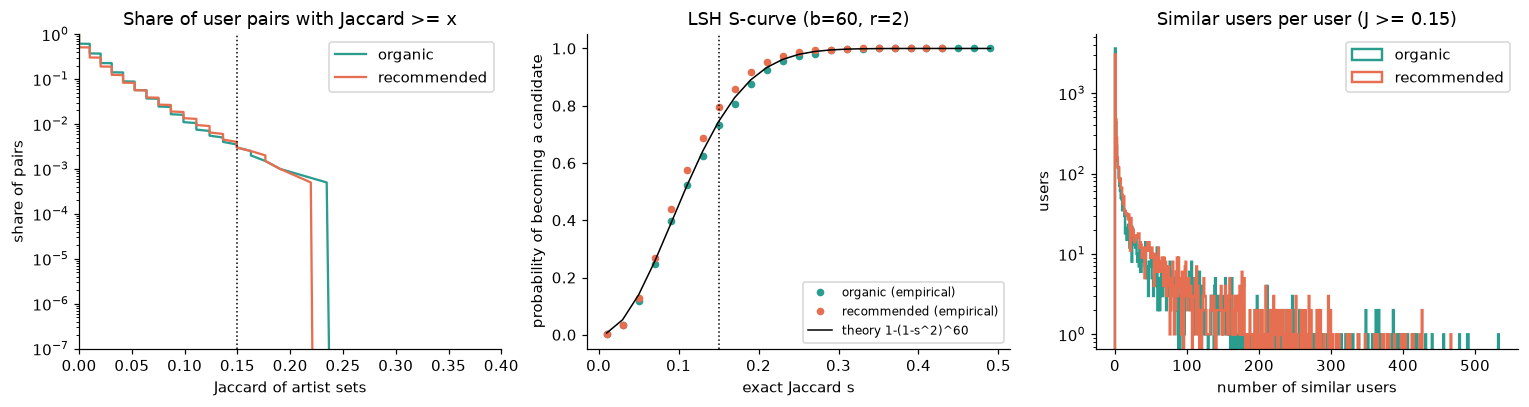

In [9]:
b, r = 60, 2   # chosen configuration (high recall for T_SIM, small share of pairs examined)
edges = np.linspace(0, 0.5, 26); mid = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for s in Jv:
    v = np.sort(Jv[s]); ccdf = 1 - np.arange(1, len(v) + 1) / len(v)
    sub = np.linspace(0, len(v) - 1, 2000).astype(int)
    ax[0].plot(v[sub], ccdf[sub], color=COL[s], label=s)
ax[0].set(xscale="linear", yscale="log", xlim=(0, 0.4), ylim=(1e-7, 1), title="Share of user pairs with Jaccard >= x",
          xlabel="Jaccard of artist sets", ylabel="share of pairs"); ax[0].legend()
ax[0].axvline(T_SIM, color="k", ls=":", lw=1)
for s in Jv:
    c = cand_store[(b, r, s)]
    C = np.zeros((E, E), dtype=bool); C[c // E, c % E] = True
    bi = np.digitize(Jv[s], edges) - 1; ok_ = (bi >= 0) & (bi < len(mid))
    tot = np.bincount(bi[ok_], minlength=len(mid)); hit = np.bincount(bi[ok_], weights=C[iu][ok_], minlength=len(mid))
    keep = tot >= 20
    ax[1].plot(mid[keep], hit[keep] / tot[keep], "o", color=COL[s], ms=4, label=f"{s} (empirical)")
ax[1].plot(mid, 1 - (1 - mid ** r) ** b, "k-", lw=1, label=f"theory 1-(1-s^{r})^{b}")
ax[1].axvline(T_SIM, color="k", ls=":", lw=1)
ax[1].set(title="LSH S-curve (b=60, r=2)", xlabel="exact Jaccard s", ylabel="probability of becoming a candidate"); ax[1].legend(fontsize=8)
bins = np.arange(0, max(nb["organic"].max(), nb["recommended"].max()) + 2)
for s in nb:
    ax[2].hist(nb[s], bins=bins, histtype="step", color=COL[s], lw=1.6, label=s)
ax[2].set(yscale="log", title=f"Similar users per user (J >= {T_SIM})", xlabel="number of similar users", ylabel="users"); ax[2].legend()
plt.tight_layout(); plt.show()

In [10]:
for s in Jv:
    pass
add_verdict("B MinHash/LSH", "mean user-user Jaccard", Jv["organic"].mean(), Jv["recommended"].mean(), "narrower")
add_verdict("B MinHash/LSH", f"pairs with J >= {T_SIM} (LSH-found, b=60 r=2)",
            float(L[(L.b == 60) & (L.stream == "organic")]["similar pairs found"].iloc[0]),
            float(L[(L.b == 60) & (L.stream == "recommended")]["similar pairs found"].iloc[0]), "narrower")
add_verdict("B MinHash/LSH", "mean similar users per user", nb["organic"].mean(), nb["recommended"].mean(), "narrower")
del Jd, C

**Reading method B.** The first panel shows whether one stream has a heavier tail of similar user pairs. The S-curve
checks that LSH behaves as the theory predicts, and the table shows what share of all user pairs we had to examine to find the
similar ones (that saving is the point of LSH at larger scale).

## Method C: frequent itemsets with A-Priori and PCY (Week 5)

**Idea.** A *basket* is the set of distinct artists a user plays (real listens) in one session. If recommendations narrow
taste, a few artist combinations should recur much more often.

To make the two streams comparable:
* same users as in method B,
* at most `CAP` distinct artists per basket (the first ones in time), baskets with at least 2 artists,
* at most `MAX_BASKETS_PER_USER` baskets per user and stream (heavy users must not dominate),
* **the same number of baskets of every size in both streams**, so basket length cannot explain a difference.

Algorithms (own implementation, numpy): pass 1 counts items (PCY also hashes every pair into buckets), pass 2 counts pairs of
frequent items only (PCY additionally requires a frequent bucket). We verify both against a naive counter.

In [11]:
m = (ratio_arr >= REAL_PCT) & (art_arr >= 0) & eligB[uidx_arr]
bs, bo, ba, bu = sid_arr[m], org_arr[m].astype(np.int64), art_arr[m].astype(np.int64), uidx_arr[m]
_, fi = np.unique((((bs * 2 + bo) << 21)) | ba, return_index=True); fi.sort()      # distinct artist per (session, stream)
bs, bo, ba, bu = bs[fi], bo[fi], ba[fi], bu[fi]
gb = bs * 2 + bo
keep = rank_in_group(gb) < CAP
gb, ba, bu, bo = gb[keep], ba[keep], bu[keep], bo[keep]
order = np.argsort(gb, kind="stable"); gb, ba, bu, bo = gb[order], ba[order], bu[order], bo[order]
start = np.r_[0, np.flatnonzero(gb[1:] != gb[:-1]) + 1]
size = np.diff(np.r_[start, len(gb)])
b_user, b_org = bu[start], bo[start]
print(f"baskets (session x stream, any size): organic {int(((b_org == 1)).sum()):,}, recommended {int((b_org == 0).sum()):,}")

bi = np.flatnonzero(size >= 2)
bi = bi[rng.permutation(len(bi))]
gu = b_user[bi] * 2 + b_org[bi]
bi = bi[rank_in_group(gu) < MAX_BASKETS_PER_USER]           # random cap per user and stream
chosen = {0: [], 1: []}
for k in range(2, CAP + 1):
    ik = bi[size[bi] == k]; o = ik[b_org[ik] == 1]; rc = ik[b_org[ik] == 0]
    n_ = min(len(o), len(rc))
    if n_:
        chosen[1].append(rng.choice(o, n_, replace=False)); chosen[0].append(rng.choice(rc, n_, replace=False))
Mk = {s: {} for s in ("organic", "recommended")}
for k in range(2, CAP + 1):
    for s, v in (("organic", 1), ("recommended", 0)):
        idx_k = np.concatenate([i_ for i_ in chosen[v] if len(i_) and size[i_[0]] == k] or [np.array([], dtype=int)])
        if len(idx_k):
            Mk[s][k] = np.sort(ba[start[idx_k][:, None] + np.arange(k)], axis=1)
n_baskets = {s: sum(len(M_) for M_ in Mk[s].values()) for s in Mk}
print("matched baskets per stream:", n_baskets)
sz = pd.DataFrame({s: {k: len(M_) for k, M_ in Mk[s].items()} for s in Mk})
print("basket size distribution identical in both streams:", bool((sz["organic"] == sz["recommended"]).all()),
      f"| mean size {np.average(sz.index, weights=sz['organic']):.2f}")

baskets (session x stream, any size): organic 1,223,856, recommended 1,011,412


matched baskets per stream: {'organic': 359604, 'recommended': 359604}
basket size distribution identical in both streams: True | mean size 7.77


In [12]:
CH = 40_000
NB = 1 << 22
ART_MAX = int(art_arr.max()) + 1
bucket_of = lambda a, b: ((a.astype(np.int64) * 1000003) ^ (b.astype(np.int64) * 998244353)) % NB

def count_items(Mk_):
    return np.bincount(np.concatenate([M_.ravel() for M_ in Mk_.values()]), minlength=ART_MAX)

def iter_pairs(Mk_):
    for k, M_ in Mk_.items():
        i_, j_ = np.triu_indices(k, 1)
        for s0 in range(0, len(M_), CH):
            Mc = M_[s0:s0 + CH]
            yield Mc[:, i_], Mc[:, j_]

def pcy_pass1(Mk_, min_count):
    bc = np.zeros(NB, dtype=np.int64)
    for a, b in iter_pairs(Mk_):
        bc += np.bincount(bucket_of(a, b).ravel(), minlength=NB)
    return bc >= min_count

def count_pairs(Mk_, min_count, item_cnt, bucket_ok=None):
    freq = item_cnt >= min_count
    parts, occ = [], 0
    for a, b in iter_pairs(Mk_):
        v = freq[a] & freq[b]
        if bucket_ok is not None:
            v &= bucket_ok[bucket_of(a, b)]
        a, b = a[v], b[v]; occ += len(a)
        parts.append(np.unique((a.astype(np.int64) << 21) | b, return_counts=True))
    ku = np.concatenate([u for u, _ in parts]); kc = np.concatenate([c for _, c in parts])
    uu, inv = np.unique(ku, return_inverse=True)
    cc = np.bincount(inv, weights=kc).astype(np.int64)
    return uu, cc, occ

# ---- correctness check against a naive counter on a small subset ----
from itertools import combinations
from collections import Counter
small = {k: M_[:150] for k, M_ in Mk["recommended"].items()}
naive = Counter()
for M_ in small.values():
    for row in M_:
        naive.update(combinations(row.tolist(), 2))
mc_small = 3
uu, cc, _ = count_pairs(small, mc_small, count_items(small))
mine = {(int(k >> 21), int(k & ((1 << 21) - 1))): int(c) for k, c in zip(uu, cc) if c >= mc_small}
ref = {k: c for k, c in naive.items() if c >= mc_small}
print("A-Priori pair counts equal the naive counter on a subset:", mine == ref, f"({len(ref)} frequent pairs)")

A-Priori pair counts equal the naive counter on a subset: True (1226 frequent pairs)


In [13]:
res = {}
for s in Mk:
    M = n_baskets[s]; mc = int(np.ceil(min(SUPPORTS) * M))
    item_cnt = count_items(Mk[s])
    t1 = time.time(); uu, cc, occ = count_pairs(Mk[s], mc, item_cnt); t_ap = time.time() - t1
    t1 = time.time(); bok = pcy_pass1(Mk[s], mc)
    uu2, cc2, occ2 = count_pairs(Mk[s], mc, item_cnt, bok); t_pcy = time.time() - t1
    same = np.array_equal(uu[cc >= mc], uu2[cc2 >= mc]) and np.array_equal(cc[cc >= mc], cc2[cc2 >= mc])
    res[s] = dict(M=M, mc=mc, item_cnt=item_cnt, keys=uu, cnt=cc)
    print(f"{s}: {M:,} baskets, min count {mc}; frequent items {int((item_cnt >= mc).sum()):,}")
    print(f"   A-Priori: {len(uu):,} candidate pairs counted ({occ:,} occurrences), {int((cc >= mc).sum()):,} frequent, {t_ap:.0f} s")
    print(f"   PCY     : {len(uu2):,} candidate pairs counted ({occ2:,} occurrences), same frequent pairs: {same}, {t_pcy:.0f} s "
          f"(bucket filter keeps {bok.mean():.1%} of buckets)")

organic: 359,604 baskets, min count 72; frequent items 5,382
   A-Priori: 2,311,469 candidate pairs counted (10,434,255 occurrences), 10,938 frequent, 1 s
   PCY     : 18,786 candidate pairs counted (1,893,281 occurrences), same frequent pairs: True, 1 s (bucket filter keeps 0.3% of buckets)


recommended: 359,604 baskets, min count 72; frequent items 5,647
   A-Priori: 2,774,952 candidate pairs counted (10,833,284 occurrences), 11,282 frequent, 1 s
   PCY     : 20,847 candidate pairs counted (1,852,606 occurrences), same frequent pairs: True, 1 s (bucket filter keeps 0.3% of buckets)


In [14]:
mask21 = (1 << 21) - 1
rows = []
for s in Mk:
    R = res[s]; M = R["M"]; ic = R["item_cnt"]
    for sup in SUPPORTS:
        mc = int(np.ceil(sup * M))
        fi_ = ic >= mc
        fp = R["cnt"] >= mc
        a, b = R["keys"][fp] >> 21, R["keys"][fp] & mask21
        lift = R["cnt"][fp] * M / (ic[a] * ic[b])
        rows.append({"stream": s, "support": sup, "min count": mc, "frequent artists": int(fi_.sum()),
                     "occurrence coverage": ic[fi_].sum() / ic.sum(), "frequent pairs": int(fp.sum()),
                     "pairs per frequent artist": fp.sum() / max(fi_.sum(), 1), "median lift": np.median(lift),
                     "share lift>=10": (lift >= 10).mean()})
C_ = pd.DataFrame(rows)
print(C_.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))

     stream  support  min count  frequent artists  occurrence coverage  frequent pairs  pairs per frequent artist  median lift  share lift>=10
    organic    0.000         72              5382                0.869           10938                      2.032        3.873           0.191
    organic    0.001        180              2776                0.763            2472                      0.890        4.209           0.169
    organic    0.001        360              1539                0.651             816                      0.530        4.387           0.138
    organic    0.002        720               766                0.510             201                      0.262        5.200           0.124
recommended    0.000         72              5647                0.890           11282                      1.998        5.628           0.283
recommended    0.001        180              2998                0.782            2447                      0.816        6.497           0.307

baskets containing at least one frequent pair (support 0.0005): organic 36.9%, recommended 35.6%
frequent pairs: organic 2,472, recommended 2,447, shared 1,269 (Jaccard 0.348)


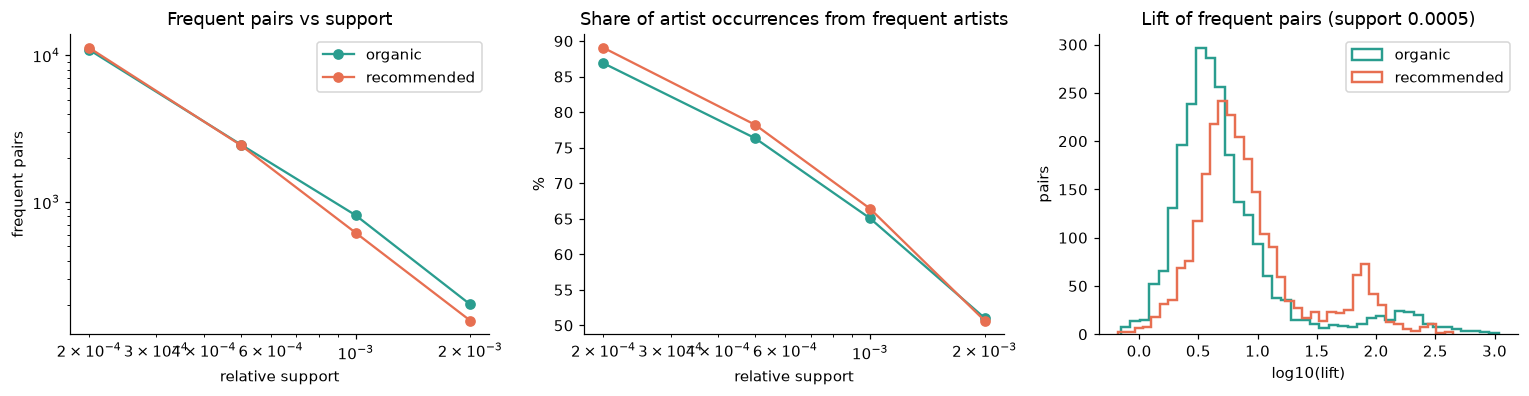

In [15]:
# share of baskets that contain at least one frequent pair, at the main support
cov = {}
for s in Mk:
    R = res[s]; mc = int(np.ceil(SUP * R["M"])); fk = R["keys"][R["cnt"] >= mc]
    hit = tot = 0
    for k, M_ in Mk[s].items():
        i_, j_ = np.triu_indices(k, 1)
        for s0 in range(0, len(M_), CH):
            Mc = M_[s0:s0 + CH]
            keys = (Mc[:, i_].astype(np.int64) << 21) | Mc[:, j_]
            pos_ = np.searchsorted(fk, keys); pos_[pos_ >= len(fk)] = 0
            hit += int((fk[pos_] == keys).any(axis=1).sum()); tot += len(Mc)
    cov[s] = hit / tot
fk = {s: res[s]["keys"][res[s]["cnt"] >= int(np.ceil(SUP * res[s]["M"]))] for s in Mk}
shared = len(np.intersect1d(fk["organic"], fk["recommended"]))
print(f"baskets containing at least one frequent pair (support {SUP}): organic {cov['organic']:.1%}, recommended {cov['recommended']:.1%}")
print(f"frequent pairs: organic {len(fk['organic']):,}, recommended {len(fk['recommended']):,}, shared {shared:,} "
      f"(Jaccard {shared / (len(fk['organic']) + len(fk['recommended']) - shared):.3f})")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))
for s in Mk:
    d = C_[C_.stream == s]
    ax[0].plot(d["support"], d["frequent pairs"], "o-", color=COL[s], label=s)
    ax[1].plot(d["support"], d["occurrence coverage"] * 100, "o-", color=COL[s], label=s)
    R = res[s]; mc = int(np.ceil(SUP * R["M"])); fp = R["cnt"] >= mc
    a_, b_ = R["keys"][fp] >> 21, R["keys"][fp] & mask21
    lift = R["cnt"][fp] * R["M"] / (R["item_cnt"][a_] * R["item_cnt"][b_])
    ax[2].hist(np.log10(lift), bins=40, histtype="step", color=COL[s], lw=1.6, label=s)
ax[0].set(xscale="log", yscale="log", title="Frequent pairs vs support", xlabel="relative support", ylabel="frequent pairs"); ax[0].legend()
ax[1].set(xscale="log", title="Share of artist occurrences from frequent artists", xlabel="relative support", ylabel="%")
ax[2].set(title=f"Lift of frequent pairs (support {SUP})", xlabel="log10(lift)", ylabel="pairs"); ax[2].legend()
plt.tight_layout(); plt.show()

R = {s: C_[(C_.stream == s) & (C_.support == SUP)].iloc[0] for s in Mk}
add_verdict("C frequent itemsets", f"frequent pairs (support {SUP})", R["organic"]["frequent pairs"], R["recommended"]["frequent pairs"], "narrower")
add_verdict("C frequent itemsets", "artist occurrence coverage by frequent artists", R["organic"]["occurrence coverage"], R["recommended"]["occurrence coverage"], "narrower")
add_verdict("C frequent itemsets", "baskets containing a frequent pair", cov["organic"], cov["recommended"], "narrower")
add_verdict("C frequent itemsets", "median lift of frequent pairs", R["organic"]["median lift"], R["recommended"]["median lift"], "narrower")

In [16]:
# top association rules by lift (anonymous artist ids), main support
for s in Mk:
    Rr = res[s]; mc = int(np.ceil(SUP * Rr["M"])); fp = Rr["cnt"] >= mc
    a_, b_, c_ = Rr["keys"][fp] >> 21, Rr["keys"][fp] & mask21, Rr["cnt"][fp]
    ic = Rr["item_cnt"]
    t = pd.DataFrame({"artist A": a_, "artist B": b_, "baskets with both": c_,
                      "confidence A->B": c_ / ic[a_], "confidence B->A": c_ / ic[b_],
                      "lift": c_ * Rr["M"] / (ic[a_] * ic[b_])}).sort_values("lift", ascending=False).head(8)
    print(f"--- {s}: top rules by lift (support {SUP}) ---")
    print(t.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

--- organic: top rules by lift (support 0.0005) ---
 artist A  artist B  baskets with both  confidence A->B  confidence B->A     lift
   343815   1034475                243             0.89             0.82 1,089.03
   343815    784605                231             0.85             0.67   880.11
   784605   1034475                238             0.69             0.81   836.08
   784605   1193472                205             0.59             0.66   685.31
   196937    862091                275             0.90             0.56   654.20
   196937    699323                263             0.86             0.54   632.05
   196937    307441                260             0.85             0.52   614.78
   307441    345924                203             0.41             0.80   578.27
--- recommended: top rules by lift (support 0.0005) ---
 artist A  artist B  baskets with both  confidence A->B  confidence B->A   lift
   371949   1108407                340             0.50             0.84 4

**Reading method C.** More frequent pairs, a higher share of baskets covered by them, and higher lifts mean a few artist
combinations explain more of the listening (narrower). Fewer and weaker patterns mean the listening is more scattered
(broader). The pair-set overlap tells us whether the two streams even share the same patterns.

## Putting the three methods together

In [17]:
V = pd.DataFrame(verdict)
pd.set_option("display.width", 200)
print(V.to_string(index=False, float_format=lambda x: f"{x:,.4f}"))
counts = V.groupby("method")["recommended is"].value_counts().unstack(fill_value=0)
print()
print(counts.to_string())

             method                                         metric     organic  recommended  relative difference recommended is
        A diversity                      distinct artists (median)     65.0000      78.0000               0.2000        broader
        A diversity                 artist entropy (bits) (median)      5.6005       6.1261               0.0939        broader
        A diversity                        mainstreamness (median)      2.2868       2.5133               0.0990       narrower
      B MinHash/LSH                         mean user-user Jaccard      0.0169       0.0147              -0.1338        broader
      B MinHash/LSH     pairs with J >= 0.15 (LSH-found, b=60 r=2) 38,156.0000  46,650.0000               0.2226       narrower
      B MinHash/LSH                    mean similar users per user     14.8785      17.5723               0.1810       narrower
C frequent itemsets                frequent pairs (support 0.0005)  2,472.0000   2,447.0000             

## Conclusion (default parameters: real listen >= 50 %, 100 tracks, 50 artists, support 0.05 %)

**The three methods do not give one answer, and that is the finding.** Recommendations do not simply narrow listening.

| Method | What it says about the recommended stream | Robust? |
|---|---|---|
| A. Diversity | **Broader**: about 11 more distinct artists per 100 tracks and about 0.5 bit more entropy, for roughly 75-80 % of users. It also plays slightly more popular tracks. | Yes: same sign in all six configurations, confidence intervals exclude 0. |
| B. MinHash/LSH | **Mixed.** The bulk of user pairs is slightly *less* similar (mean Jaccard 0.0147 vs 0.0169), but the share of users that have at least one similar neighbour (J >= 0.15) is higher (48 % vs 39 %). The most extreme pairs (J >= 0.3) are more common among organic listening (2142 vs 894 pairs). | LSH itself is validated (S-curve, recall 0.87-0.90 with 4 % of pairs checked); the direction of the effect depends on the threshold. |
| C. Frequent itemsets | **Mixed.** The number of frequent pairs is practically equal (2,472 vs 2,447) and so is the share of baskets containing one (36.9 % vs 35.6 %). The *typical* frequent pair has a higher lift in the recommended stream (median 6.5 vs 4.2), but the strongest rules are tighter in the organic stream (lift up to 1,089 vs 447). Only about 35 % of frequent pairs occur in both streams. | A-Priori and PCY give identical results and match a naive counter; PCY counted about 100x fewer candidate pairs. |

**How to read this.** On *how many different artists a user hears*, recommendations broaden. On *which artists go together*,
the recommended stream plays more moderately tight combinations, while the most extreme tight clusters are organic. Taken
together this is better described as **broader but more templated** than as narrower, and the two streams largely use
different combinations.

**Limits.** All results are associations. Users and recommender influence each other, and users who accept recommendations may
differ to begin with. "First N distinct tracks/artists" favours early listening. Artist IDs are anonymous, so we cannot say *which*
music the high-lift pairs are (they may simply be artists on the same album or playlist). Results are for Yambda-50M only.
Audio embeddings are not used here; they are analysed in `03_embeddings_sound_analysis.ipynb`.